# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import WHUOPTSARDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import ResizeToTensor

## Visualize images and masks

Total number of patches: 100


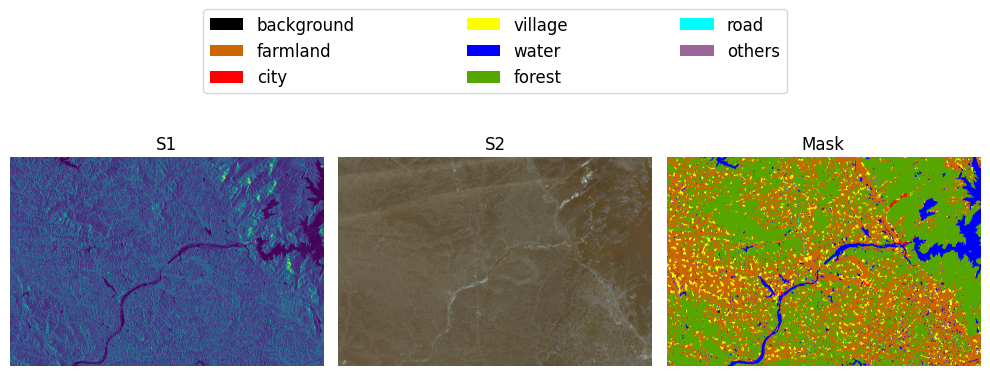

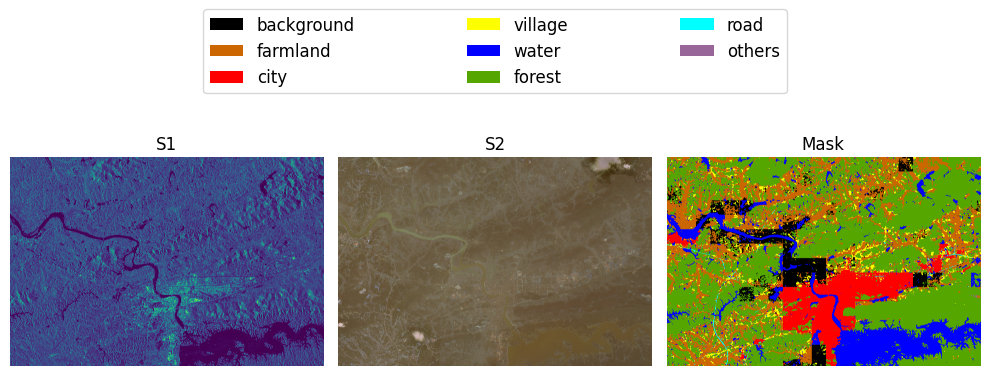

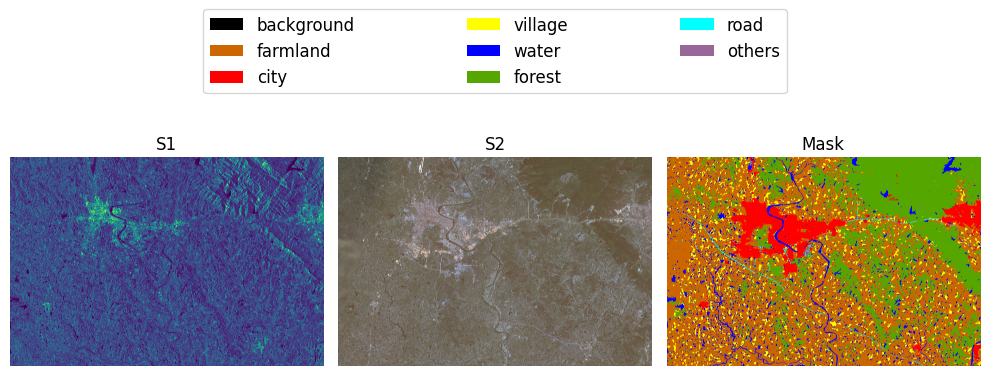

In [ ]:
dataset_config = {
    "data_dir": "./data/whu_opt_sar",
    "imagery": "s1 and s2"
}
dataset = WHUOPTSARDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(50);
dataset.show_image(60);

In [ ]:
dataset_config = {
    "data_dir": "./data/whu_opt_sar",
    "imagery": "s2"
}
dataset = WHUOPTSARDataset(dataset_config)

dataset.data_distribution_table()

,Number of pixels
background,17197904.0
farmland,726786586.0
city,99383747.0
village,105867099.0
water,288696914.0
forest,803737687.0
road,11004003.0
others,5227645.0


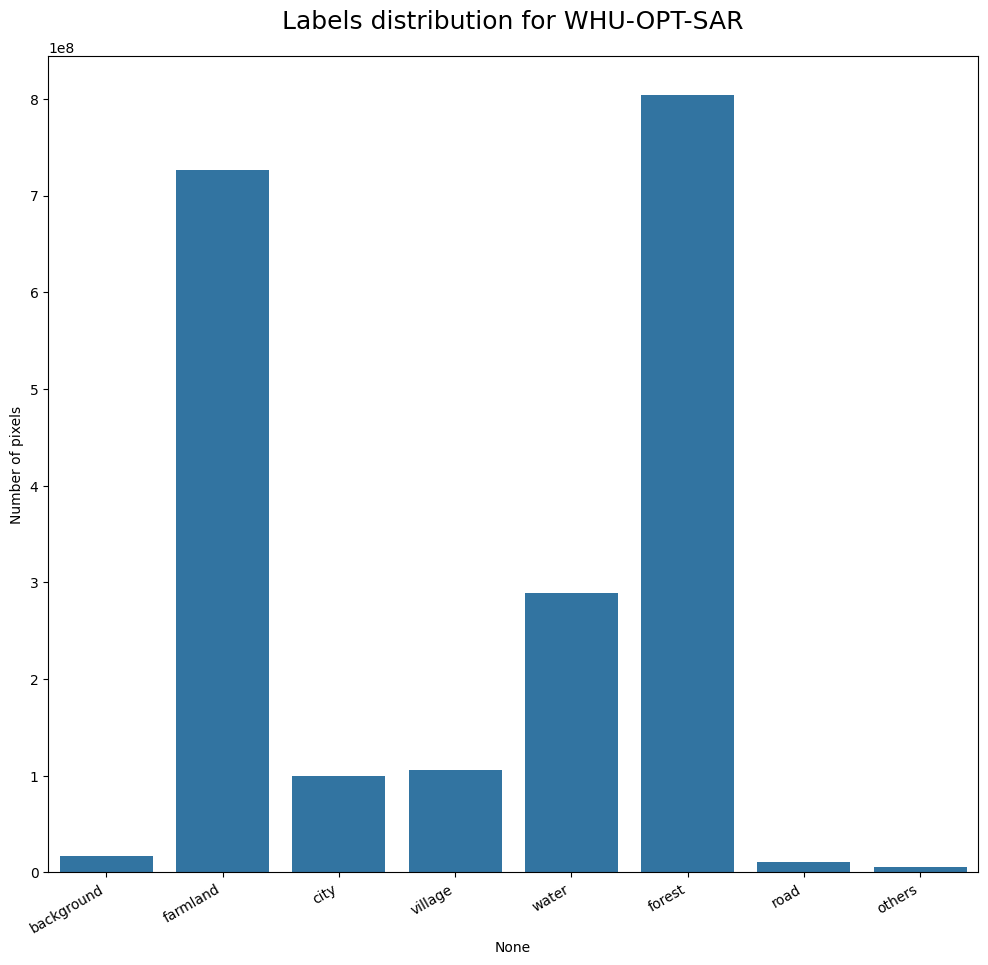

In [6]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/whu_opt_sar/",
    "csv_file": "./data/whu_opt_sar/whu_opt_sar_train.csv",
    "selection": "rgb",
    "imagery": "s2",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = WHUOPTSARDataset(train_dataset_config)
len(train_dataset)

60

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/experiements/whu_opt_sar"
model_config = {
    "num_classes": 8, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [13]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2026-01-08 08:06:05,555 INFO Starting training.
training: 100%|██████████| 8/8 [03:20<00:00, 25.11s/it] 
2026-01-08 08:09:26,496 INFO epoch: 1, time: 201, loss:  0.77670
testing on train set: 100%|██████████| 8/8 [03:19<00:00, 24.91s/it]
2026-01-08 08:12:47,362 INFO IOU:0.04009706068357522, IOU mean:0.03126728204395594, IOU per Class:[7.04346084e-03 1.17689617e-01 1.96805907e-02 1.01623240e-03
 6.70926320e-02 3.75308490e-02 0.00000000e+00 8.48743009e-05]
training: 100%|██████████| 8/8 [03:12<00:00, 24.09s/it] 
2026-01-08 08:16:00,103 INFO epoch: 2, time: 193, loss:  0.74282
testing on train set: 100%|██████████| 8/8 [03:18<00:00, 24.82s/it]
2026-01-08 08:19:18,666 INFO IOU:0.05316420723565402, IOU mean:0.03887599944872849, IOU per Class:[1.90612847e-04 1.22069505e-01 2.12275867e-02 1.06099030e-03
 6.85878642e-02 9.78477616e-02 0.00000000e+00 2.36749897e-05]
training: 100%|██████████| 8/8 [03:21<00:00, 25.22s/it]
2026-01-08 08:22:40,436 INFO epoch: 3, time: 202, loss:  0.72191
testing o

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/whu_opt_sar/",
    "csv_file": "./data/whu_opt_sar/whu_opt_sar_val.csv",
    "selection": "rgb",
    "imagery": "s2",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = WHUOPTSARDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiements/whu_opt_sar/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

20


2026-01-08 10:14:20,302 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiements/whu_opt_sar/checkpoint.pth.tar
2026-01-08 10:14:23,156 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiements/whu_opt_sar/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 5/5 [01:41<00:00, 20.38s/it]


[{'IOU': 0.37656546051111417,
  'IOU mean': 0.16291823147438816,
  'IOU per Class': array([0.        , 0.13257472, 0.21777217, 0.00699067, 0.26702859,
         0.67897971, 0.        , 0.        ])}]

## Predictions

2026-01-13 08:07:31,559 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiements/whu_opt_sar/checkpoint.pth.tar
2026-01-13 08:07:31,983 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiements/whu_opt_sar/checkpoint.pth.tar at epoch 11


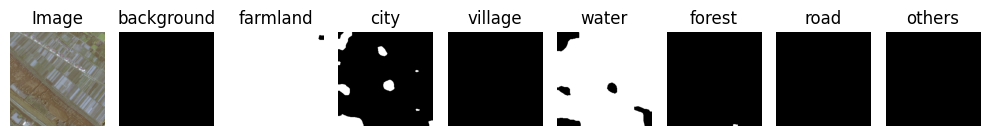

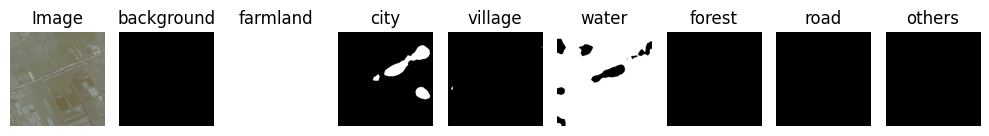

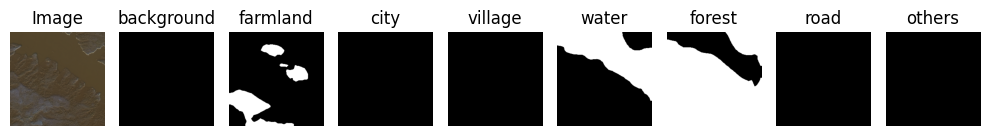

In [ ]:
model_path = "./data/experiements/whu_opt_sar/checkpoint.pth.tar"
labels = ["background","farmland","city","village","water","forest","road","others"]
transform = MinMaxNormTranspose()
model.load_model(model_path)

image = image_loader("./data/whu_opt_sar/optical/NH49E011017.tif")[:256,:256,:3]
fig = model.predict_masks(image, labels, transform)

image = image_loader("./data/whu_opt_sar/optical/NH49E013018.tif")[:256,:256,:3]
fig = model.predict_masks(image, labels, transform)

image = image_loader("./data/whu_opt_sar/optical/NI49E021011.tif")[:256,:256,:3]
fig = model.predict_masks(image, labels, transform)